# Notebook 04: Adaptive Shot Allocation

## Objective

This notebook investigates adaptive allocation of quantum measurement shots.

Instead of executing a fixed number of shots for every workload, the
runtime starts with a small measurement budget and allocates additional
shots only when the current statistical evidence is insufficient.

We will:

1. Build a QAOA Max-Cut circuit using Qiskit.
2. Execute the circuit using Qiskit Aer.
3. Collect measurement outcomes in batches.
4. Estimate expected quality and statistical uncertainty.
5. Use confidence bounds to make runtime decisions.
6. Allocate additional shots when the result is uncertain.
7. Compare adaptive allocation with a fixed-shot strategy.
8. Measure shot savings and quality-decision outcomes.

## Research question

Can adaptive shot allocation reduce quantum measurement resources
while maintaining reliable quality decisions?

## Important limitation

This notebook uses local Aer simulation. It measures shot counts and
statistical behavior, not real QPU execution time or cloud cost.

In [3]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Define the quantum workload

We use the same three-node Max-Cut graph as Notebook 03.

Edges:

(0, 1), (1, 2), (0, 2)

Each edge has weight 1.

The objective is to estimate the expected cut value produced by
a fixed QAOA circuit.

The exact optimal cut is 2.

However, the expected cut of our QAOA circuit may be lower than 2.
The runtime will evaluate the measured expected cut against a
minimum acceptable quality threshold.

In [4]:
edges = [
    (0, 1, 1),
    (1, 2, 1),
    (0, 2, 1)
]

num_qubits = 3


def calculate_cut_value(assignment):

    total_cut = 0

    for u, v, weight in edges:
        if assignment[u] != assignment[v]:
            total_cut += weight

    return total_cut


print("Number of qubits:", num_qubits)
print("Maximum possible cut:", 2)

Number of qubits: 3
Maximum possible cut: 2


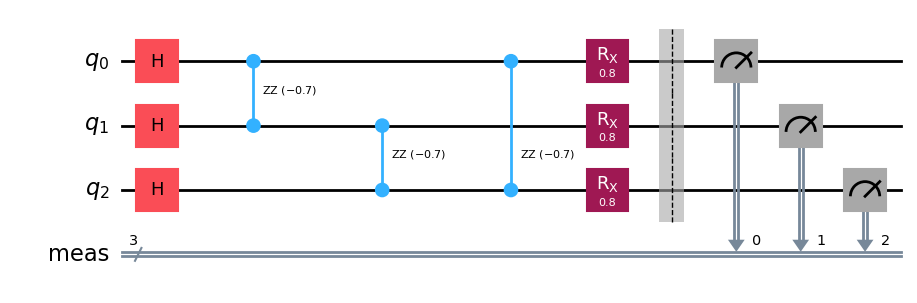

In [5]:
gamma = 0.7
beta = 0.4


def build_qaoa_circuit(measure=False):

    qc = QuantumCircuit(num_qubits)

    # Initial superposition
    for qubit in range(num_qubits):
        qc.h(qubit)

    # Cost unitary
    for u, v, weight in edges:
        qc.rzz(-gamma * weight, u, v)

    # Mixer unitary
    for qubit in range(num_qubits):
        qc.rx(2 * beta, qubit)

    if measure:
        qc.measure_all()

    return qc


state_circuit = build_qaoa_circuit(measure=False)
measurement_circuit = build_qaoa_circuit(measure=True)

display(measurement_circuit.draw("mpl"))

In [6]:
statevector = Statevector.from_instruction(state_circuit)

ideal_probabilities = statevector.probabilities_dict()


def decode_bitstring(bitstring):

    clean_bits = bitstring.replace(" ", "")

    # Align Qiskit bitstring positions with graph nodes
    return tuple(int(bit) for bit in clean_bits[::-1])


ideal_expected_cut = 0.0

for bitstring, probability in ideal_probabilities.items():

    assignment = decode_bitstring(bitstring)

    cut_value = calculate_cut_value(assignment)

    ideal_expected_cut += probability * cut_value


print("Ideal expected cut:", ideal_expected_cut)

Ideal expected cut: 1.918421120407589


## 2. Adaptive shot allocation strategy

A fixed-shot strategy always executes the same number of shots.

For example:

Fixed strategy:
    Execute 3000 shots.
    Calculate the result.
    Stop.

An adaptive strategy starts with a smaller budget.

Adaptive strategy:
    Execute 200 pilot shots.
    Estimate expected quality and uncertainty.
    Check the quality requirement.

    If evidence is sufficient:
        Stop.

    Otherwise:
        Execute another batch of shots.
        Update the estimate.
        Check again.

    Stop when:
        The result is accepted,
        The result is rejected, or
        The maximum shot budget is reached.

The adaptive strategy can save measurements when a decision
becomes clear before the maximum budget is consumed.

## 3. Confidence bounds for sequential decisions

We use Hoeffding's inequality because the Max-Cut observable is bounded.

For this graph:

0 <= C(x) <= 3

Let:

N       = cumulative number of shots
C_hat   = estimated expected cut
delta   = total allowed failure probability
t       = sequential inspection number, starting from 1

To account for repeated inspection, allocate the failure probability:

delta_t = delta / (t * (t + 1))

The sum of delta_t over all inspection numbers is delta.

The Hoeffding confidence radius is:

r_t = (C_max - C_min)
      * sqrt( ln(2 / delta_t) / (2 * N) )

Confidence bounds:

LCB = C_hat - r_t
UCB = C_hat + r_t

Decision:

PASS:
    LCB >= quality threshold

FAIL:
    UCB < quality threshold

UNCERTAIN:
    Otherwise

This is a conservative sequential decision rule. The allocation of
delta across inspections provides an overall error-probability
guarantee under the assumptions of independent bounded samples.

The interval is not necessarily as narrow as a normal or Student's
t interval, but it is useful for this sequential stopping experiment.

In [7]:
simulator = AerSimulator()

compiled_circuit = transpile(
    measurement_circuit,
    simulator,
    optimization_level=1
)

print("Circuit compiled for AerSimulator.")

Circuit compiled for AerSimulator.


In [8]:
def run_measurement_batch(shots, seed):

    job = simulator.run(
        compiled_circuit,
        shots=shots,
        seed_simulator=seed
    )

    result = job.result()

    return result.get_counts()


def counts_to_samples(counts):

    samples = []

    for bitstring, frequency in counts.items():

        assignment = decode_bitstring(bitstring)

        cut_value = calculate_cut_value(assignment)

        samples.extend([cut_value] * frequency)

    return np.asarray(samples, dtype=float)


# Test one batch

test_counts = run_measurement_batch(
    shots=200,
    seed=42
)

test_samples = counts_to_samples(test_counts)

print("Measurement counts:", test_counts)
print("Number of samples:", len(test_samples))
print("Measured mean:", np.mean(test_samples))

Measurement counts: {'011': 46, '110': 21, '001': 31, '100': 34, '010': 25, '101': 37, '000': 3, '111': 3}
Number of samples: 200
Measured mean: 1.94


In [9]:
def calculate_sequential_bounds(
    samples,
    inspection_number,
    total_delta=0.05,
    observable_min=0,
    observable_max=3
):

    n = len(samples)

    mean_value = np.mean(samples)

    # Allocate error probability across sequential inspections
    delta_t = total_delta / (
        inspection_number * (inspection_number + 1)
    )

    observable_range = observable_max - observable_min

    radius = observable_range * math.sqrt(
        math.log(2 / delta_t) / (2 * n)
    )

    lower_bound = mean_value - radius
    upper_bound = mean_value + radius

    return {
        "shots": n,
        "inspection": inspection_number,
        "mean": mean_value,
        "delta_t": delta_t,
        "radius": radius,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "ci_width": upper_bound - lower_bound
    }


# Example using the pilot batch

pilot_statistics = calculate_sequential_bounds(
    test_samples,
    inspection_number=1
)

for key, value in pilot_statistics.items():
    print(f"{key}: {value}")

shots: 200
inspection: 1
mean: 1.94
delta_t: 0.025
radius: 0.31399936191043815
lower_bound: 1.6260006380895617
upper_bound: 2.253999361910438
ci_width: 0.6279987238208762


In [10]:
QUALITY_THRESHOLD = 1.2


def make_quality_decision(statistics, threshold):

    lower = statistics["lower_bound"]
    upper = statistics["upper_bound"]

    if lower >= threshold:
        return "PASS"

    elif upper < threshold:
        return "FAIL"

    else:
        return "UNCERTAIN"


decision = make_quality_decision(
    pilot_statistics,
    QUALITY_THRESHOLD
)

print("Runtime decision:", decision)

Runtime decision: PASS


## 4. Define the adaptive allocation policy

We configure:

Initial pilot shots = 200
Additional batch   = 200
Maximum shots      = 3000
Quality threshold  = 1.2

The runtime uses the following policy:

1. Start with 200 shots.
2. Calculate the cumulative expected cut.
3. Calculate sequential confidence bounds.
4. Accept if the lower bound meets the threshold.
5. Reject if the upper bound is below the threshold.
6. If uncertain, allocate another batch.
7. Stop if the maximum budget is reached.

The policy does not assume that more shots always produce a better
measured mean.

Additional shots improve statistical evidence by increasing the
sample size. The estimated mean may move up or down as new samples
are collected.

In [11]:
def adaptive_shot_allocation(
    quality_threshold=1.2,
    initial_shots=200,
    batch_size=200,
    max_shots=3000,
    total_delta=0.05,
    seed=100
):

    all_samples = []
    history = []

    current_shots = 0
    inspection_number = 0

    while current_shots < max_shots:

        # Determine the next batch size
        remaining_budget = max_shots - current_shots

        next_batch = min(
            batch_size if current_shots > 0 else initial_shots,
            remaining_budget
        )

        # Execute another quantum measurement batch
        counts = run_measurement_batch(
            shots=next_batch,
            seed=seed + inspection_number
        )

        batch_samples = counts_to_samples(counts)

        all_samples.extend(batch_samples.tolist())

        current_shots += next_batch
        inspection_number += 1

        # Calculate cumulative statistics
        statistics = calculate_sequential_bounds(
            np.asarray(all_samples),
            inspection_number=inspection_number,
            total_delta=total_delta
        )

        decision = make_quality_decision(
            statistics,
            quality_threshold
        )

        history.append({
            **statistics,
            "batch_shots": next_batch,
            "decision": decision
        })

        print(
            f"Inspection {inspection_number} | "
            f"Shots: {current_shots} | "
            f"Mean: {statistics['mean']:.4f} | "
            f"LCB: {statistics['lower_bound']:.4f} | "
            f"UCB: {statistics['upper_bound']:.4f} | "
            f"Decision: {decision}"
        )

        # Stop when a decision is reached
        if decision in ["PASS", "FAIL"]:
            break

    # If budget is exhausted without a clear decision
    if history[-1]["decision"] == "UNCERTAIN":
        final_decision = "BUDGET_EXHAUSTED"
    else:
        final_decision = history[-1]["decision"]

    return {
        "history": pd.DataFrame(history),
        "samples": np.asarray(all_samples),
        "total_shots": current_shots,
        "final_decision": final_decision
    }

In [12]:
adaptive_result = adaptive_shot_allocation(
    quality_threshold=1.2,
    initial_shots=200,
    batch_size=200,
    max_shots=3000,
    total_delta=0.05,
    seed=500
)

adaptive_history = adaptive_result["history"]

print("\nFinal decision:", adaptive_result["final_decision"])
print("Total shots used:", adaptive_result["total_shots"])

display(adaptive_history)

Inspection 1 | Shots: 200 | Mean: 1.9400 | LCB: 1.6260 | UCB: 2.2540 | Decision: PASS

Final decision: PASS
Total shots used: 200


,shots,inspection,mean,delta_t,radius,lower_bound,upper_bound,ci_width,batch_shots,decision
0,200,1,1.94,0.025,0.313999,1.626001,2.253999,0.627999,200,PASS


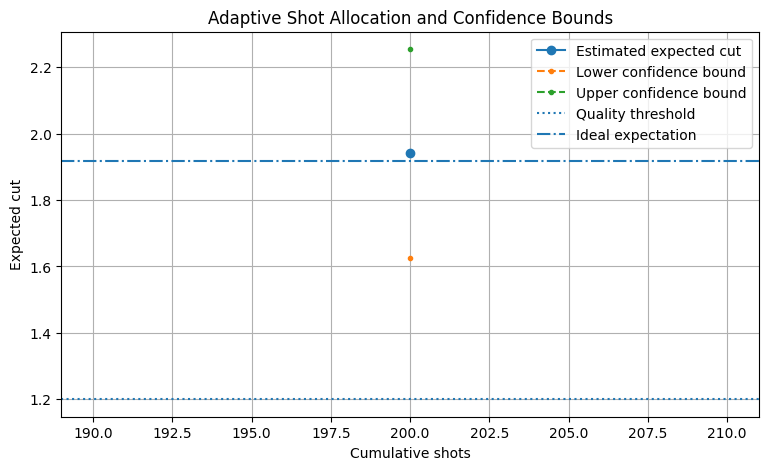

In [13]:
plt.figure(figsize=(9, 5))

history = adaptive_history

plt.plot(
    history["shots"],
    history["mean"],
    marker="o",
    label="Estimated expected cut"
)

plt.plot(
    history["shots"],
    history["lower_bound"],
    marker=".",
    linestyle="--",
    label="Lower confidence bound"
)

plt.plot(
    history["shots"],
    history["upper_bound"],
    marker=".",
    linestyle="--",
    label="Upper confidence bound"
)

plt.axhline(
    QUALITY_THRESHOLD,
    linestyle=":",
    label="Quality threshold"
)

plt.axhline(
    ideal_expected_cut,
    linestyle="-.",
    label="Ideal expectation"
)

plt.xlabel("Cumulative shots")
plt.ylabel("Expected cut")
plt.title("Adaptive Shot Allocation and Confidence Bounds")

plt.legend()
plt.grid(True)
plt.show()

In [14]:
FIXED_SHOTS = 3000

fixed_counts = run_measurement_batch(
    shots=FIXED_SHOTS,
    seed=900
)

fixed_samples = counts_to_samples(fixed_counts)

fixed_mean = np.mean(fixed_samples)

adaptive_shots = adaptive_result["total_shots"]

shot_savings = FIXED_SHOTS - adaptive_shots

shot_savings_percentage = (
    shot_savings / FIXED_SHOTS
) * 100

comparison = pd.DataFrame([
    {
        "strategy": "Fixed",
        "shots_used": FIXED_SHOTS,
        "estimated_quality": fixed_mean
    },
    {
        "strategy": "Adaptive",
        "shots_used": adaptive_shots,
        "estimated_quality": np.mean(adaptive_result["samples"])
    }
])

display(comparison)

print("Shot savings:", shot_savings)
print(f"Shot savings percentage: {shot_savings_percentage:.2f}%")

,strategy,shots_used,estimated_quality
0,Fixed,3000,1.918667
1,Adaptive,200,1.940000


Shot savings: 2800
Shot savings percentage: 93.33%


## 6. Interpret fixed versus adaptive allocation

Fixed allocation always uses the configured maximum number of shots.

Adaptive allocation can stop earlier if its statistical evidence
is sufficient for a quality decision.

Shot savings are:

Shot savings = Fixed shots - Adaptive shots

Shot savings percentage =

    (Fixed shots - Adaptive shots) / Fixed shots * 100

Important:

A lower shot count alone does not prove that adaptive allocation
is better.

We must also check whether the quality decision is reliable.

A fair evaluation should report:

1. Total shots used.
2. Final runtime decision.
3. Quality-decision correctness relative to the ideal expectation.
4. Confidence interval behavior.
5. Frequency of budget exhaustion.
6. Shot savings.

The adaptive and fixed runs use independent measurement samples,
so their estimated means will not necessarily be identical.

In [15]:
fixed_statistics = calculate_sequential_bounds(
    fixed_samples,
    inspection_number=1,
    total_delta=0.05
)

fixed_decision = make_quality_decision(
    fixed_statistics,
    QUALITY_THRESHOLD
)

adaptive_final = adaptive_history.iloc[-1]

decision_comparison = pd.DataFrame([
    {
        "strategy": "Fixed",
        "shots": FIXED_SHOTS,
        "mean": fixed_statistics["mean"],
        "lower_bound": fixed_statistics["lower_bound"],
        "upper_bound": fixed_statistics["upper_bound"],
        "decision": fixed_decision
    },
    {
        "strategy": "Adaptive",
        "shots": adaptive_result["total_shots"],
        "mean": adaptive_final["mean"],
        "lower_bound": adaptive_final["lower_bound"],
        "upper_bound": adaptive_final["upper_bound"],
        "decision": adaptive_result["final_decision"]
    }
])

display(decision_comparison)

,strategy,shots,mean,lower_bound,upper_bound,decision
0,Fixed,3000,1.918667,1.837592,1.999741,PASS
1,Adaptive,200,1.940000,1.626001,2.253999,PASS


## 6. Interpret fixed versus adaptive allocation

Fixed allocation always uses the configured maximum number of shots.

Adaptive allocation can stop earlier if its statistical evidence
is sufficient for a quality decision.

Shot savings are:

Shot savings = Fixed shots - Adaptive shots

Shot savings percentage =

    (Fixed shots - Adaptive shots) / Fixed shots * 100

Important:

A lower shot count alone does not prove that adaptive allocation
is better.

We must also check whether the quality decision is reliable.

A fair evaluation should report:

1. Total shots used.
2. Final runtime decision.
3. Quality-decision correctness relative to the ideal expectation.
4. Confidence interval behavior.
5. Frequency of budget exhaustion.
6. Shot savings.

The adaptive and fixed runs use independent measurement samples,
so their estimated means will not necessarily be identical.

In [16]:
fixed_statistics = calculate_sequential_bounds(
    fixed_samples,
    inspection_number=1,
    total_delta=0.05
)

fixed_decision = make_quality_decision(
    fixed_statistics,
    QUALITY_THRESHOLD
)

adaptive_final = adaptive_history.iloc[-1]

decision_comparison = pd.DataFrame([
    {
        "strategy": "Fixed",
        "shots": FIXED_SHOTS,
        "mean": fixed_statistics["mean"],
        "lower_bound": fixed_statistics["lower_bound"],
        "upper_bound": fixed_statistics["upper_bound"],
        "decision": fixed_decision
    },
    {
        "strategy": "Adaptive",
        "shots": adaptive_result["total_shots"],
        "mean": adaptive_final["mean"],
        "lower_bound": adaptive_final["lower_bound"],
        "upper_bound": adaptive_final["upper_bound"],
        "decision": adaptive_result["final_decision"]
    }
])

display(decision_comparison)

,strategy,shots,mean,lower_bound,upper_bound,decision
0,Fixed,3000,1.918667,1.837592,1.999741,PASS
1,Adaptive,200,1.940000,1.626001,2.253999,PASS


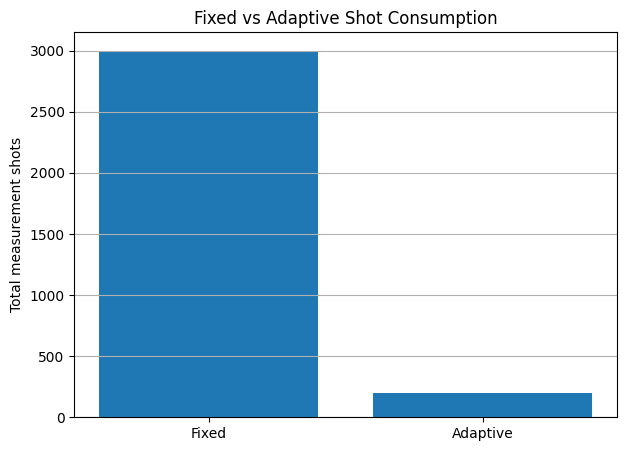

In [17]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison["strategy"],
    comparison["shots_used"]
)

plt.ylabel("Total measurement shots")
plt.title("Fixed vs Adaptive Shot Consumption")

plt.grid(axis="y")
plt.show()

In [18]:
from scipy.stats import norm

def estimate_required_shots(
    pilot_samples,
    epsilon=0.1,
    confidence=0.95
):

    pilot_samples = np.asarray(pilot_samples)

    sample_std = np.std(
        pilot_samples,
        ddof=1
    )

    z_value = norm.ppf(
        (1 + confidence) / 2
    )

    required_shots = math.ceil(
        (z_value * sample_std / epsilon) ** 2
    )

    return {
        "pilot_shots": len(pilot_samples),
        "sample_std": sample_std,
        "target_error": epsilon,
        "required_shots_estimate": required_shots
    }


planning_result = estimate_required_shots(
    pilot_samples=test_samples,
    epsilon=0.1,
    confidence=0.95
)

for key, value in planning_result.items():
    print(f"{key}: {value}")

pilot_shots: 200
sample_std: 0.3420305901861931
target_error: 0.1
required_shots_estimate: 45


## 8. Research interpretation

This notebook demonstrates a basic adaptive measurement strategy.

### Observation 1: Fixed allocation

A fixed strategy may consume more shots than necessary when the
quality decision becomes clear early.

### Observation 2: Adaptive allocation

An adaptive strategy can stop after sufficient statistical evidence
has been collected.

### Observation 3: Quality constraints

The runtime makes decisions using confidence bounds rather than
only the estimated mean.

### Observation 4: Resource awareness

Shot allocation is a resource-management decision.

The runtime must balance statistical precision against the available
measurement budget.

### Observation 5: Uncertain outcomes

Sometimes the maximum shot budget is reached while the result
remains uncertain.

The runtime must report this honestly rather than incorrectly
accepting or rejecting the result.

## Limitations

1. Experiments use local Aer simulation.
2. The observable is bounded Max-Cut objective value.
3. The quality threshold is an experimental parameter.
4. The variance-based shot estimate is approximate.
5. The sequential Hoeffding policy is conservative.
6. Real hardware noise, queue time, and provider costs are not modeled.
7. The experiment does not yet optimize shot allocation across
   multiple circuits or multiple workload tasks.